# 03 — Threshold options for R2 and the trade-off

Can R2 produce clearly fewer alerts while keeping detection? Success criteria (requirements note): R2 alerts −30% or more, overall detection down by at most 2 percentage points, no key laundering type down by more than 5 points.

In [1]:
%load_ext autoreload
%autoreload 2

import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "db.py").exists())
sys.path.insert(0, str(ROOT))

from src import review, rules
from src.db import connect

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
con = connect()
rules.prepare(con)
RESULTS = ROOT / "docs" / "results"
FIGURES = ROOT / "docs" / "figures"

## 1. Threshold grid for R2
27 settings: minimum weekly inflow (5k / 10k / 20k), minimum outflow share (70 / 80 / 90%) and an outflow cap (none / 130% / 110% of inflow, the fix proposed in finding F-007).

In [2]:
grid_rows = [review.evaluate(con, rules.BASELINE, "baseline")[0]]
for inflow, low, cap in itertools.product([5000, 10000, 20000], [0.7, 0.8, 0.9], [1e9, 1.3, 1.1]):
    if (inflow, low, cap) == (5000, 0.7, 1e9):
        continue
    params = {**rules.BASELINE, "r2_min_inflow": inflow, "r2_min_outflow_share": low, "r2_max_outflow_share": cap}
    label = f"inflow {inflow // 1000}k, out ≥ {low:.0%}, cap {'none' if cap > 10 else f'{cap:.0%}'}"
    grid_rows.append(review.evaluate(con, params, label)[0])

grid = pd.DataFrame(grid_rows).set_index("option")
grid_check = review.check_criteria(grid, "baseline")
grid_view = pd.concat([
    grid[["r2_alerts_per_month", "r2_precision_pct", "detection_pct"]],
    grid_check[["r2_alert_change_pct", "detection_change_pp", "worst_key_typology_change_pp", "meets_all"]],
], axis=1)
print(f"Settings meeting all criteria: {int(grid_check['meets_all'].sum())} of {len(grid) - 1}")
grid_view.round(2)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Settings meeting all criteria: 0 of 26


,r2_alerts_per_month,r2_precision_pct,detection_pct,r2_alert_change_pct,detection_change_pp,worst_key_typology_change_pp,meets_all
option,,,,,,,
baseline,13835.00,1.30,24.25,0.00,0.00,0.00,False
"inflow 5k, out ≥ 70%, cap 130%",5443.44,1.21,16.30,-60.65,-7.95,-19.28,False
"inflow 5k, out ≥ 70%, cap 110%",4324.22,1.21,15.36,-68.74,-8.88,-20.83,False
"inflow 5k, out ≥ 80%, cap none",12988.78,1.32,23.66,-6.12,-0.58,-1.10,False
"inflow 5k, out ≥ 80%, cap 130%",4597.22,1.26,15.65,-66.77,-8.59,-20.14,False
"inflow 5k, out ≥ 80%, cap 110%",3478.00,1.27,14.72,-74.86,-9.53,-21.69,False
"inflow 5k, out ≥ 90%, cap none",12195.00,1.30,22.77,-11.85,-1.48,-2.01,False
"inflow 5k, out ≥ 90%, cap 130%",3803.44,1.18,14.71,-72.51,-9.54,-21.17,False
"inflow 5k, out ≥ 90%, cap 110%",2684.22,1.17,13.76,-80.60,-10.49,-22.72,False


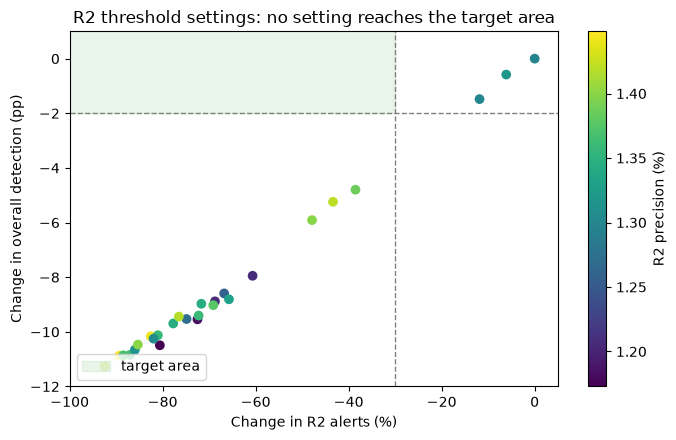

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(grid_check["r2_alert_change_pct"], grid_check["detection_change_pp"], c=grid["r2_precision_pct"], cmap="viridis")
ax.axvline(-30, color="grey", ls="--", lw=1)
ax.axhline(-2, color="grey", ls="--", lw=1)
ax.fill_between([-100, -30], -2, 1, color="tab:green", alpha=0.1, label="target area")
ax.set(xlabel="Change in R2 alerts (%)", ylabel="Change in overall detection (pp)",
       title="R2 threshold settings: no setting reaches the target area", xlim=(-100, 5), ylim=(-12, 1))
ax.legend(loc="lower left")
fig.colorbar(ax.collections[0], label="R2 precision (%)")
fig.tight_layout()
fig.savefig(FIGURES / "03_r2_threshold_grid.png", dpi=150)

## 2. Why thresholds do not help: true and false R2 alerts look the same on amounts
Compare baseline R2 alerts on what else happens in the alert week.

In [4]:
rules.run_rules(con, rules.BASELINE)
con.sql("""
    SELECT
        CASE WHEN a.is_true THEN 'true alert' ELSE 'false alert' END AS alert,
        COUNT(*) AS alerts,
        ROUND(MEDIAN(f.inflow)) AS median_inflow,
        ROUND(MEDIAN(f.outflow / f.inflow), 2) AS median_out_in_ratio,
        ROUND(100 * AVG(f.cash_in::INT), 1) AS pct_with_cash_in,
        ROUND(100 * AVG(f.cross_border_in::INT), 1) AS pct_cross_border_in,
        ROUND(100 * AVG(f.cross_border_out::INT), 1) AS pct_cross_border_out,
        ROUND(100 * AVG((f.cash_in OR f.cross_border_in OR f.cross_border_out)::INT), 1) AS pct_any_risk_leg
    FROM alerts_eval a
    JOIN flows_week f USING (account, wk)
    WHERE a.rule = 'R2'
    GROUP BY ALL
""").df()

,alert,alerts,median_inflow,median_out_in_ratio,pct_with_cash_in,pct_cross_border_in,pct_cross_border_out,pct_any_risk_leg
0,true alert,1840,13564.0,1.73,28.4,27.0,43.9,71.6
1,false alert,140141,13031.0,1.64,21.8,12.7,21.9,43.6


## 3. The five options
A: keep current rules. B: raise R2's minimum inflow to £10,000. C: R2 only alerts when the week includes a cash deposit or a cross-border payment. D: C, but R2 still alerts on inflows of £30,000 or more without such a payment. E: D plus a 182-day R1 lookback.

In [5]:
rows, typologies, steady, detected = [], [], {}, {}
for label, params in review.OPTIONS.items():
    row, typ = review.evaluate(con, params, label)
    rows.append(row)
    typologies.append(typ)
    steady[label] = review.steady_state_alerts(con)
    detected[label] = review.detected_set(con)

options = pd.DataFrame(rows).set_index("option")
baseline_label = next(iter(review.OPTIONS))
options_check = review.check_criteria(options, baseline_label)
steady = pd.DataFrame(steady).T.add_suffix("_steady_per_month")
options_table = pd.concat([options, options_check, steady], axis=1)
options_table.round(2).T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,A. Keep current rules,B. Raise R2 minimum inflow to 10k,C. R2 only with a cash or cross-border leg,"D. C, but R2 also alerts on inflows of 30k+",E. D + R1 lookback 182 days
r2_alerts_per_month,13835.0,8504.67,6108.22,7803.11,7803.11
r2_precision_pct,1.3,1.39,2.11,1.76,1.76
r2_detected_accounts,1393,954,952,1033,1033
r2_unique_detections,952,573,549,625,571
total_alerts_per_month,29909.56,24579.22,22182.78,23877.67,27792.78
total_fte,83.08,68.28,61.62,66.33,77.2
total_precision_pct,1.21,1.23,1.41,1.34,1.6
detected_accounts,1916,1537,1513,1589,1854
detection_pct,24.25,19.45,19.15,20.11,23.46
key: Deposit-Send,22.61,16.71,20.19,20.58,24.64


## 4. What each option gains and loses, in laundering accounts

In [6]:
base_set = detected[baseline_label]
acct_typ = con.sql("SELECT account, UNNEST(typologies) AS typology FROM laundering_accounts").df()

def by_type(accounts: set) -> pd.Series:
    return acct_typ[acct_typ["account"].isin(accounts)]["typology"].value_counts()

changes = {}
for label, accounts in detected.items():
    if label == baseline_label:
        continue
    changes[(label, "gained")] = by_type(accounts - base_set)
    changes[(label, "lost")] = by_type(base_set - accounts)
gain_loss = pd.DataFrame(changes).fillna(0).astype(int)
gain_loss.loc["total accounts"] = [len(detected[l] - base_set) if k == "gained" else len(base_set - detected[l]) for l, k in gain_loss.columns]
gain_loss

B. Raise R2 minimum inflow to 10k      C. R2 only with a cash or cross-border leg      D. C, but R2 also alerts on inflows of 30k+      E. D + R1 lookback 182 days     
                                             gained lost                                     gained lost                                      gained lost                      gained lost
typology                                                                                                                                                                                  
Bipartite                                         0   21                                          0   23                                           0   22                          20   18
Cash_Withdrawal                                   0    4                                          0    2                                           0    1                           7    1
Cycle                                             0   39                                          0   89                                           0   56                          13   53
Deposit-Send                                      0   61                                          0   25                                           0   21                          42   21
Fan_In                                            0    4                                          0   10                                           0    6                           3    6
Fan_Out                                           0   22                                          0   20                                           0   17                          21   13
Gather-Scatter                                    0   23                                          0   24                                           0   19                          14   18
Layered_Fan_In                                    0   26                                          0   45                                           0   37                          12   37
Layered_Fan_Out                                   0   92                                          0   64                                           0   61                          45   59
Over-Invoicing                                    0    2                                          0    1                                           0    1                           6    1
Scatter-Gather                                    0   22                                          0   27                                           0   26                          19   24
Single_large                                      0    2                                          0    9                                           0    3                          23    3
Smurfing                                          0    9                                          0    6                                           0    6                           2    6
Stacked Bipartite                                 0   27                                          0   39                                           0   35                          16   31
Structuring                                       0   25                                          0   19                                           0   16                           2   16
total accounts                                    0  379                                          0  403                                           0  327                         245  307

## 5. Is the effect stable month to month?

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,A. vs A (%),B. vs A (%),C. vs A (%),D. vs A (%),E. vs A (%)
month,,,,,
2022-11-01,0.0,-19.1,-26.5,-20.1,-20.1
2022-12-01,0.0,-17.9,-25.0,-19.2,-19.2
2023-01-01,0.0,-17.2,-24.8,-19.0,-15.2
2023-02-01,0.0,-17.7,-25.6,-19.7,-8.8
2023-03-01,0.0,-17.4,-25.6,-20.0,-4.0
2023-04-01,0.0,-17.9,-25.7,-20.1,-1.6
2023-05-01,0.0,-17.6,-26.2,-20.9,-1.5
2023-06-01,0.0,-18.1,-26.6,-21.1,-1.1
2023-07-01,0.0,-17.9,-26.4,-21.0,-0.3


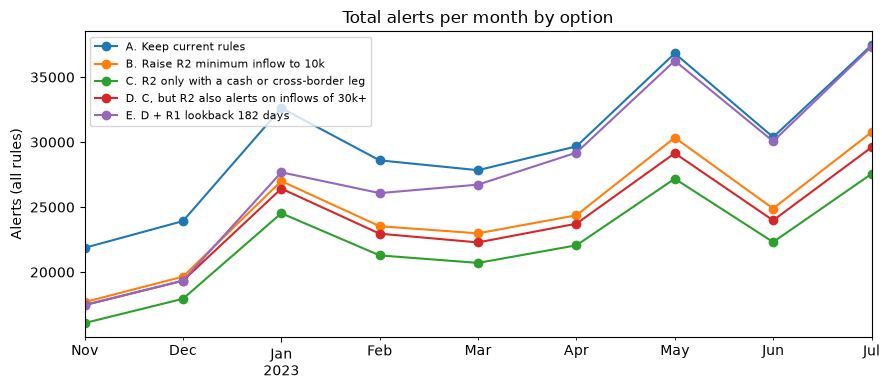

In [7]:
monthly = {}
for label, params in review.OPTIONS.items():
    rules.run_rules(con, params)
    m = rules.monthly(con)
    m = m[(m["month"] >= rules.FULL_MONTHS[0]) & (m["month"] <= rules.FULL_MONTHS[1])]
    monthly[label] = m.groupby("month")["alerts"].sum()
monthly = pd.DataFrame(monthly)

fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o")
ax.set(title="Total alerts per month by option", xlabel="", ylabel="Alerts (all rules)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "03_options_monthly.png", dpi=150)
monthly.div(monthly[baseline_label], axis=0).sub(1).mul(100).round(1).rename(columns=lambda c: c[:2] + " vs A (%)")

## 6. Alerts vs detection per option

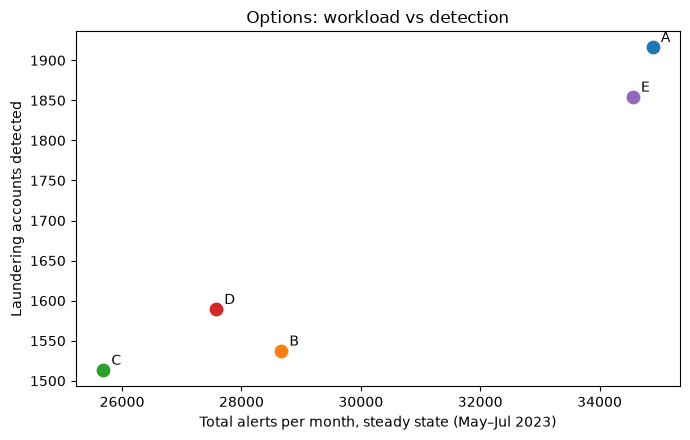

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for label, r in options_table.iterrows():
    ax.scatter(r["total_steady_per_month"], r["detected_accounts"], s=80)
    ax.annotate(label.split(".")[0], (r["total_steady_per_month"], r["detected_accounts"]),
                textcoords="offset points", xytext=(6, 4))
ax.set(xlabel="Total alerts per month, steady state (May–Jul 2023)", ylabel="Laundering accounts detected",
       title="Options: workload vs detection")
fig.tight_layout()
fig.savefig(FIGURES / "03_options_tradeoff.png", dpi=150)

## 7. Sensitivity: review time per alert
Investigator FTE in steady state for 10, 20 (working assumption) and 40 minutes per alert.

In [9]:
sensitivity = pd.DataFrame({
    f"{m} min per alert": options_table["total_steady_per_month"] * m / 60 / rules.REVIEW_HOURS_PER_FTE_MONTH
    for m in (10, 20, 40)
})
sensitivity["FTE saved vs A at 20 min"] = sensitivity["20 min per alert"].iloc[0] - sensitivity["20 min per alert"]
sensitivity.round(1)

,10 min per alert,20 min per alert,40 min per alert,FTE saved vs A at 20 min
A. Keep current rules,48.5,96.9,193.8,0.0
B. Raise R2 minimum inflow to 10k,39.8,79.6,159.2,17.3
C. R2 only with a cash or cross-border leg,35.7,71.3,142.7,25.6
"D. C, but R2 also alerts on inflows of 30k+",38.3,76.6,153.2,20.3
E. D + R1 lookback 182 days,48.0,96.0,192.0,0.9


In [10]:
grid_view.to_csv(RESULTS / "r2_threshold_grid.csv")
options_table.to_csv(RESULTS / "options_comparison.csv")
pd.concat(typologies, axis=1).to_csv(RESULTS / "options_detection_by_typology.csv")
gain_loss.to_csv(RESULTS / "options_gained_lost_accounts.csv")

## 8. Findings
_To be written after reviewing the outputs above._